# Error analysis
Comparison of the best custom model with PatchCore and PaDiM. 

In [2]:
from sklearn.metrics import roc_auc_score, precision_recall_curve
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import numpy as np

CLASSES = ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw',
           'tile', 'toothbrush', 'transistor', 'wood', 'zipper']
MODELS = ['custom', 'patchcore', 'padim']

# experiment folder and file suffix of each model (the custom model is evaluated with blur sigma 4)
EXPERIMENTS = {
    'custom': ('experiments/feature_reconstruction/layer23_multihead_c256', '_sigma4'),
    'patchcore': ('experiments/patchcore/resnet18', ''),
    'padim': ('experiments/padim/resnet18', ''),
}

FIGURES_DIR = Path('figures/error_analysis')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## **Part 1**: comparing quantitative results. 
This part doesn't require retraining models, it only reads the anomaly scores of each image saved into the log files (`image_scores*.csv`). The image score of each model is its main one: top-1% of the map for the custom model, the native score for PatchCore and PaDiM. For PatchCore and PaDiM, I also computed the anomaly score as the top-1% of the map for a fair comparison with the custom model.

Mean over the 15 classes and selection metric per class ((Image AUROC + AUPRO) / 2, as for the ablations).

In [3]:
results = {model: pd.read_csv(Path(exp_dir) / f"overall_results{suffix}.csv", index_col=0)
           for model, (exp_dir, suffix) in EXPERIMENTS.items()}

summary = pd.DataFrame({model: df.loc['MEAN', ['image_auroc', 'pixel_auroc', 'aupro']] for model, df in results.items()}).T
summary['selection'] = (summary.image_auroc + summary.aupro) / 2
display(summary.round(4))

selection = pd.DataFrame({model: (df.loc[CLASSES, 'image_auroc'] + df.loc[CLASSES, 'aupro']) / 2
                          for model, df in results.items()})
selection['custom - patchcore'] = selection.custom - selection.patchcore
display(selection.sort_values('custom - patchcore').round(3))

,image_auroc,pixel_auroc,aupro,selection
custom,0.9622,0.9618,0.8992,0.9307
patchcore,0.9775,0.9782,0.9283,0.9529
padim,0.8813,0.9696,0.9212,0.9012


,custom,patchcore,padim,custom - patchcore
transistor,0.875,0.957,0.864,-0.082
tile,0.863,0.912,0.873,-0.049
toothbrush,0.869,0.918,0.882,-0.049
capsule,0.916,0.954,0.874,-0.038
zipper,0.922,0.955,0.907,-0.033
pill,0.906,0.937,0.897,-0.031
screw,0.934,0.958,0.818,-0.023
grid,0.921,0.941,0.897,-0.020
cable,0.943,0.959,0.835,-0.015
metal_nut,0.956,0.971,0.941,-0.015


## 1.1: Does the aggregation method used for computing AUROC changes the model performance?

Compute image AUROC per class with the native score of PatchCore and PaDiM and with the top-1% score of the map, the same used by the custom model.

In [4]:
# Image AUROC with the native score and with the top-1% score of the map (for the custom model they coincide)
aggregation = pd.DataFrame({
    'custom (top-1%)': results['custom'].image_auroc,
    'patchcore native': results['patchcore'].image_auroc,
    'patchcore top-1%': results['patchcore'].image_auroc_top1pct,
    'padim native': results['padim'].image_auroc,
    'padim top-1%': results['padim'].image_auroc_top1pct,
}).loc[CLASSES + ['MEAN']]
display(aggregation.round(3))

,custom (top-1%),patchcore native,patchcore top-1%,padim native,padim top-1%
bottle,1.000,1.000,1.000,0.974,0.998
cable,0.992,0.979,0.995,0.771,0.857
capsule,0.933,0.983,0.981,0.838,0.902
carpet,0.989,0.984,0.979,0.986,0.989
grid,0.947,0.972,0.961,0.905,0.915
hazelnut,1.000,0.999,1.000,0.760,0.951
leather,1.000,1.000,1.000,1.000,1.000
metal_nut,1.000,0.998,0.997,0.951,0.981
pill,0.918,0.938,0.936,0.857,0.929
screw,0.918,0.947,0.955,0.720,0.681


- PatchCore is the best model on every metric. The custom model is close to PatchCore in detection (Image AUROC 0. 962 vs 0.978): the gap is mostly in
  localization (AUPRO 0.899 vs 0.928). Localization is its weak point: even PaDiM, much worse in detection,
  has a higher AUPRO in 12 classes out of 15.
- The gap is concentrated in a few classes: transistor (-0.082, AUPRO 0.79 vs 0.93), tile, toothbrush and capsule.
  On the textures (carpet, wood, leather) and on bottle the custom model is on par or slightly better.
- The low Image AUROC of PaDiM (0.881) comes from its native score (the maximum of the map): with the top-1% score it
  rises to 0.930. The top-1% score is better in almost every class, with the largest gains on hazelnut, transistor, toothbrush and cable; screw is the only class where it is worse.
- For PatchCore the two scores are almost equivalent, with a larger difference only on toothbrush.
- With the same aggregation (top-1%) the ranking does not change: PatchCore 0.982, custom 0.962, PaDiM 0.930.

## 1.2: Which defect types are hard for **all** models (intrinsic difficulty of the data)?
To answer this question I compute the image AUROC for each defect type. To do so, first I create a table containing, for each image of the test set, the anomaly score assigned to that image by all the three methods considered for the error analysis, the class of the image and the defect type. Each image is identified by its path.

In [5]:
# One row per test image, one score column per model (the three files list the same images in the same order)
dfs = []
for cls in CLASSES:
    df = None
    for model, (exp_dir, suffix) in EXPERIMENTS.items():
        scores = pd.read_csv(Path(exp_dir) / cls / f"image_scores{suffix}.csv")
        if df is None:
            df = scores[['path', 'defect_type', 'label']].copy()
            df.insert(0, 'class', cls)
        df[model] = scores['score']
    dfs.append(df)
scores = pd.concat(dfs, ignore_index=True)

print(f"{len(scores)} test images, {scores.label.sum()} defective, "
      f"{scores[scores.label == 1].groupby('class').defect_type.nunique().sum()} defect types")
scores.head(10)

1725 test images, 1258 defective, 73 defect types


,class,path,defect_type,label,custom,patchcore,padim
0,bottle,data\MVTec\bottle\test\broken_large\000.png,broken_large,1,0.401745,2.949931,28.778664
1,bottle,data\MVTec\bottle\test\broken_large\001.png,broken_large,1,0.426898,3.246136,29.467432
2,bottle,data\MVTec\bottle\test\broken_large\002.png,broken_large,1,0.461326,2.755422,28.008366
3,bottle,data\MVTec\bottle\test\broken_large\003.png,broken_large,1,0.409694,3.274290,29.654379
4,bottle,data\MVTec\bottle\test\broken_large\004.png,broken_large,1,0.411353,3.298514,31.414206
5,bottle,data\MVTec\bottle\test\broken_large\005.png,broken_large,1,0.441512,2.987136,28.285868
6,bottle,data\MVTec\bottle\test\broken_large\006.png,broken_large,1,0.426642,3.420663,29.166142
7,bottle,data\MVTec\bottle\test\broken_large\007.png,broken_large,1,0.378280,2.744619,27.104639
8,bottle,data\MVTec\bottle\test\broken_large\008.png,broken_large,1,0.408273,3.078273,34.607471
9,bottle,data\MVTec\bottle\test\broken_large\009.png,broken_large,1,0.331369,2.707739,26.237610


In [6]:
rows = []
for (cls, defect_type), group in scores[scores.label == 1].groupby(['class', 'defect_type']):
    good = scores[(scores['class'] == cls) & (scores.label == 0)]
    both = pd.concat([good, group])
    row = {'class': cls, 'defect_type': defect_type, 'n_images': len(group)}
    for model in MODELS:
        row[model] = roc_auc_score(both.label, both[model])
    rows.append(row)
defect_auroc = pd.DataFrame(rows).set_index(['class', 'defect_type'])

pd.set_option('display.max_rows', 100)
display(defect_auroc.round(3))

n_images  custom  patchcore  padim
class      defect_type                                             
bottle     broken_large                20   1.000      1.000  1.000
           broken_small                22   1.000      1.000  1.000
           contamination               21   1.000      1.000  0.988
cable      bent_wire                   13   1.000      1.000  0.972
           cable_swap                  12   0.941      0.881  0.701
           combined                    11   1.000      1.000  0.903
           cut_inner_insulation        14   1.000      0.990  0.879
           cut_outer_insulation        10   1.000      0.993  0.979
           missing_cable               12   1.000      1.000  0.588
           missing_wire                10   0.993      0.997  0.626
           poke_insulation             10   1.000      0.976  0.878
capsule    crack                       23   0.930      0.977  0.898
           faulty_imprint              22   0.879      0.988  0.767
           poke                        21   0.940      0.994  0.834
           scratch                     23   0.924      0.960  0.866
           squeeze                     20   1.000      1.000  0.948
carpet     color                       19   1.000      1.000  0.985
           cut                         17   1.000      1.000  1.000
           hole                        17   1.000      1.000  1.000
           metal_contamination         17   0.964      0.945  0.983
           thread                      19   0.979      0.976  0.964
grid       bent                        12   0.992      0.992  0.881
           broken                      12   1.000      1.000  1.000
           glue                        11   0.857      0.900  0.766
           metal_contamination         11   0.957      0.987  0.965
           thread                      11   0.922      0.978  0.905
hazelnut   crack                       18   1.000      1.000  0.754
           cut                         17   1.000      0.996  0.818
           hole                        18   1.000      1.000  0.929
           print                       17   1.000      1.000  0.806
leather    color                       19   1.000      1.000  1.000
           cut                         19   1.000      1.000  1.000
           fold                        17   1.000      1.000  1.000
           glue                        19   1.000      1.000  1.000
           poke                        18   1.000      1.000  1.000
metal_nut  bent                        25   1.000      1.000  0.975
           color                       22   1.000      0.996  0.965
           flip                        23   1.000      1.000  1.000
           scratch                     23   1.000      0.996  0.897
pill       color                       25   0.900      0.914  0.945
           combined                    17   0.980      0.991  0.982
           contamination               21   0.969      0.989  0.919
           crack                       26   0.803      0.848  0.756
           faulty_imprint              19   0.984      0.966  0.783
           pill_type                    9   1.000      1.000  0.940
           scratch                     24   0.888      0.934  0.787
screw      manipulated_front           24   0.858      0.899  0.847
           scratch_head                24   0.962      0.972  0.716
           scratch_neck                25   0.987      0.986  0.653
           thread_side                 23   0.824      0.902  0.667
           thread_top                  23   0.952      0.973  0.714
tile       crack                       17   1.000      1.000  1.000
           glue_strip                  18   1.000      1.000  1.000
           gray_stroke                 16   0.936      0.973  0.805
           oil                         18   1.000      1.000  0.995
           rough                       15   0.923      0.992  0.954
toothbrush defective                   30   0.892      0.931  0.881
transistor bent_lead 

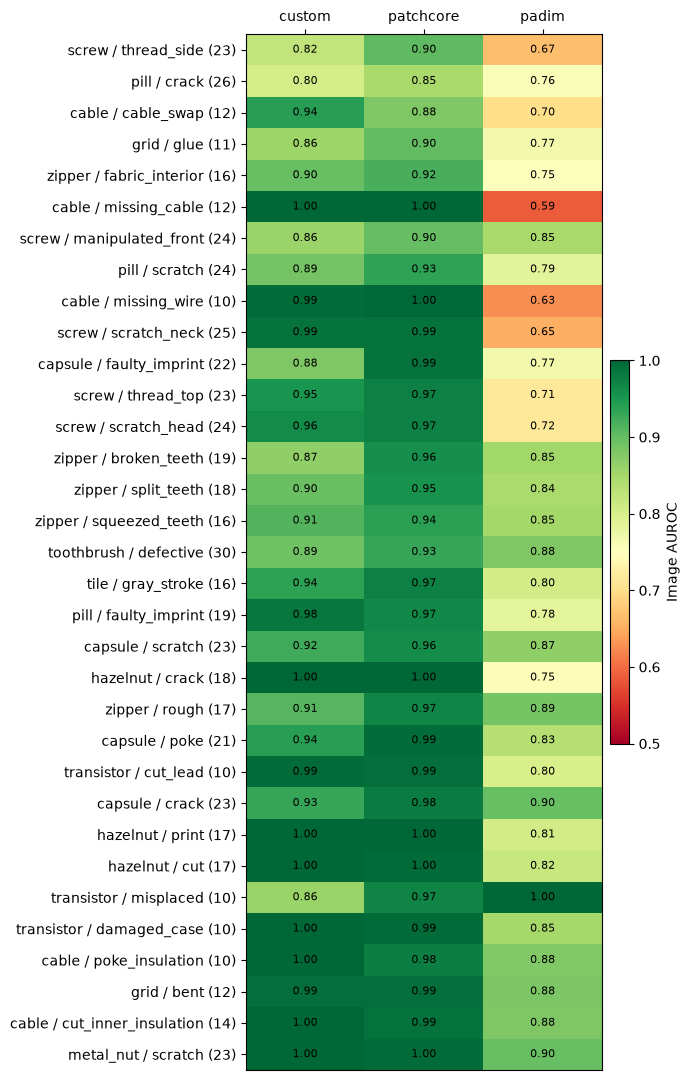

In [7]:
# Heatmap of the defect types where at least one model is below 0.9
hard = defect_auroc[defect_auroc[MODELS].min(axis=1) < 0.9]
hard = hard.loc[hard[MODELS].mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(7, 0.3 * len(hard) + 1))
im = ax.imshow(hard[MODELS].values, cmap='RdYlGn', vmin=0.5, vmax=1.0, aspect='auto')
for i in range(len(hard)):
    for j, model in enumerate(MODELS):
        ax.text(j, i, f"{hard[model].iloc[i]:.2f}", ha='center', va='center', fontsize=8)
ax.set_xticks(range(len(MODELS)), MODELS)
ax.set_yticks(range(len(hard)), [f"{c} / {d} ({n})" for (c, d), n in zip(hard.index, hard.n_images)])
ax.xaxis.tick_top()
plt.colorbar(im, ax=ax, fraction=0.05, pad=0.02, label='Image AUROC')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'defect_type_auroc.png', dpi=200, bbox_inches='tight')
plt.show()

- Most defect types are easy for the custom model and PatchCore; the hard ones are concentrated in screw, pill,
  zipper, capsule and grid, i.e. small defects or objects with a variable pose.
- Largest gaps of the custom model with respect to PatchCore: transistor/misplaced,capsule/faulty_imprint, zipper/broken_teeth, screw/thread_side. The custom model is significantly better only on cable/cable_swap.
- transistor/misplaced is a "global" anomaly (the component is missing or shifted): each patch may look normal
  locally, the anomaly is in what is expected at that position. PaDiM, which fits a Gaussian per position, detects it perfectly.
- It's important to note that each defect type could have very few test images: a single image can change the AUROC significantly, so only large differences are meaningful.

## 1.3: Defect types that are likely to be inherently difficult
I assume that defect types that are hard for every method (AUROC < 0.9 for each of them), are those for which the difficulty comes from the data itself rather than the method used.

In [8]:
print("Defect types hard for all the models (Image AUROC < 0.9 for each of them):")
display(defect_auroc[defect_auroc[MODELS].max(axis=1) < 0.9].round(3))

Defect types hard for all the models (Image AUROC < 0.9 for each of them):


,,n_images,custom,patchcore,padim
class,defect_type,,,,
pill,crack,26,0.803,0.848,0.756
screw,manipulated_front,24,0.858,0.899,0.847


Only two defect types are below 0.9 for all three models: pill/crack and screw/manipulated_front. They are the best candidates for an intrinsic difficulty of the data: thin cracks on a pill surface that is speckled also in the normal images, and a subtle deformation of the screw tip, with a screw orientation that changes from image to image.

## 1.4. False positives and false negatives
Threshold at the maximum F1 on the test set, per class and per model (the choice of anomalib's PostProcessor,
which picks it on the validation set, by default the test set). The threshold is chosen on the test set, so it is
optimistic: it is only used to count and compare the errors, not as a performance metric.

In [9]:
def f1_threshold(labels, image_scores):
    precision, recall, thresholds = precision_recall_curve(labels, image_scores)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return thresholds[np.argmax(f1[:-1])]  # the last point (recall 0) has no threshold


for model in MODELS:
    thresholds = scores.groupby('class').apply(lambda g: f1_threshold(g.label, g[model]))
    predicted = scores[model] >= scores['class'].map(thresholds)
    scores[f"{model}_wrong"] = predicted != scores.label.astype(bool)

errors = pd.DataFrame({
    model: {'false positives': (scores[f"{model}_wrong"] & (scores.label == 0)).sum(),
            'false negatives': (scores[f"{model}_wrong"] & (scores.label == 1)).sum()}
    for model in MODELS
}).T
display(errors)

,false positives,false negatives
custom,59,34
patchcore,41,34
padim,151,42


The custom model misses as many defective images as PatchCore, its extra errors are false alarms on good images. PaDiM has many more false positives, this is in part due to its native scoring of the anomaly map. Using the top-1% scoring the number of false positives and false negatives decreases as shown in the following cell.

In [10]:
padim_top1 = pd.concat([pd.read_csv(Path(EXPERIMENTS['padim'][0]) / cls / 'image_scores.csv')['score_top1pct']
                        for cls in CLASSES], ignore_index=True)  # same images, same order as `scores`
thresholds = scores.assign(s=padim_top1).groupby('class').apply(lambda g: f1_threshold(g.label, g.s))
wrong = (padim_top1 >= scores['class'].map(thresholds)) != scores.label.astype(bool)
print("PaDiM, top-1% score:", (wrong & (scores.label == 0)).sum(), "false positives,",
      (wrong & (scores.label == 1)).sum(), "false negatives")

PaDiM, top-1% score: 123 false positives, 30 false negatives


## **Part 2**: qualitative analysis
Each figure checks a finding of Part 1 on the anomaly maps. One row per image: input image, ground truth and the
maps of the three models. The title of each map refers to the classification of the **image** at the threshold of
section 1.4, not to the map: "detected" / "missed" for a defective image, "false alarm" / "ok" for a good one.
A defective image can be detected even if its map does not point to the defect.

The maps are regenerated (they are not saved): checkpoint of the custom model (blur sigma 4), memory bank of
PatchCore, PaDiM fitted again with the same seed. The three models produce maps on different scales, so each map is
divided by the 99th percentile of the values of its model on the good test images of the class: 1 is the upper end
of the normal range, and the three models share the same color scale.

The images are chosen with an explicit rule based on the scores of Part 1, not by hand.

In [23]:
import json
from functools import lru_cache
import torch
from run_experiment import build_model
from run_literature import build_literature_model, fit_literature_model
from utils.helpers import get_device
from warnings import filterwarnings
filterwarnings("ignore")

DEVICE = get_device('cuda')
CONFIGS = {model: json.load(open(Path(exp_dir) / 'config.json')) for model, (exp_dir, _) in EXPERIMENTS.items()}
CONFIGS['custom']['blur_sigma'] = 4  # final model: anomaly map smoothed with sigma 4


@lru_cache(maxsize=None)
def class_maps(cls):
    """
    Anomaly maps [N, 256, 256] of the three models on the test images of a class, divided by the 99th percentile of
    the values of the same model on the good test images of the class. Returns the test dataset and a dict
    model -> maps (same order as the dataset).
    """
    custom = build_model(CONFIGS['custom'], DEVICE,
                         checkpoint_path=Path(EXPERIMENTS['custom'][0]) / cls / 'checkpoints' / 'best_model.pth')
    patchcore = build_literature_model(CONFIGS['patchcore'], DEVICE,
                                       memory_bank_path=Path(EXPERIMENTS['patchcore'][0]) / cls / 'memory_bank.pt')
    padim, test_loader = fit_literature_model(cls, CONFIGS['padim'])  # PaDiM is not saved: fit again, same seed
    custom.eval()

    maps = {model: [] for model in MODELS}
    with torch.no_grad():
        for batch in test_loader:
            images = batch['image'].to(DEVICE)
            pred, target = custom(images)
            maps['custom'].append(custom.compute_anomaly_map(pred, target).cpu())
            maps['patchcore'].append(patchcore.predict(images)[0].cpu())
            maps['padim'].append(padim.predict(images)[0].cpu())

    dataset = test_loader.dataset
    good = np.array([sample['label'] == 0 for sample in dataset.samples])
    for model in MODELS:
        model_maps = torch.cat(maps[model])[:, 0].numpy()
        maps[model] = model_maps / np.percentile(model_maps[good], 99)
    return dataset, maps


def plot_maps(images, file_name, vmax=3):
    """
    images: list of (class, path). One row per image: input, ground truth and the normalized maps of the three
    models. The figure is saved in FIGURES_DIR.
    """
    ncols = 2 + len(MODELS)
    fig, axes = plt.subplots(len(images), ncols, figsize=(2.6 * ncols, 2.6 * len(images)),
                             squeeze=False, constrained_layout=True)
    for row, (cls, path) in enumerate(images):
        dataset, maps = class_maps(cls)
        i = [str(sample['rgb_path']) for sample in dataset.samples].index(path)
        sample = dataset[i]
        info = scores.set_index('path').loc[path]

        axes[row, 0].imshow(sample['image'].permute(1, 2, 0).numpy())
        axes[row, 0].set_ylabel(f"{cls}\n{sample['defect_type']} {Path(path).name}", fontsize=9)
        axes[row, 1].imshow(sample['mask'][0].numpy(), cmap='gray', vmin=0, vmax=1)
        for col, model in enumerate(MODELS, start=2):
            im = axes[row, col].imshow(maps[model][i], cmap='jet', vmin=0, vmax=vmax)
            if sample['label'] == 1:
                status = 'missed' if info[f'{model}_wrong'] else 'detected'
            else:
                status = 'false alarm' if info[f'{model}_wrong'] else 'ok'
            axes[row, col].set_title(f"{model}: {status}", fontsize=9)
        axes[row, 0].set_title('image' if row == 0 else '', fontsize=9)
        axes[row, 1].set_title('ground truth' if row == 0 else '', fontsize=9)
        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])

    fig.colorbar(im, ax=axes, shrink=0.6, label='map / 99th percentile of the good images')
    plt.savefig(FIGURES_DIR / file_name, dpi=150, bbox_inches='tight')
    plt.show()


def pick(df, n, column, largest=False):
    """(class, path) of the n rows of df with the lowest (or highest) value of column."""
    rows = df.nlargest(n, column) if largest else df.nsmallest(n, column)
    return list(zip(rows['class'], rows.path))

## 2.1: Global anomalies: transistor/misplaced
In section 1.2 the custom model is clearly worse than the other two on transistor/misplaced, where the component is
missing or shifted. Rule: the 2 misplaced images with the lowest custom score and, for comparison, the 2 with the
highest one.

At the threshold of section 1.4 no misplaced image is missed by the custom model only: it misses the same two images
as PatchCore. The gap in Image AUROC comes from how the other misplaced images are ranked with respect to the good
ones, not from additional missed images.

The custom model is better than PatchCore on cable/cable_swap (section 1.2), but the advantage is a small,
systematic shift of the scores that no single image shows clearly on the maps, so it is not illustrated here.

Loaded model weights from experiments\feature_reconstruction\layer23_multihead_c256\transistor\checkpoints\best_model.pth
Random seed set to 42.


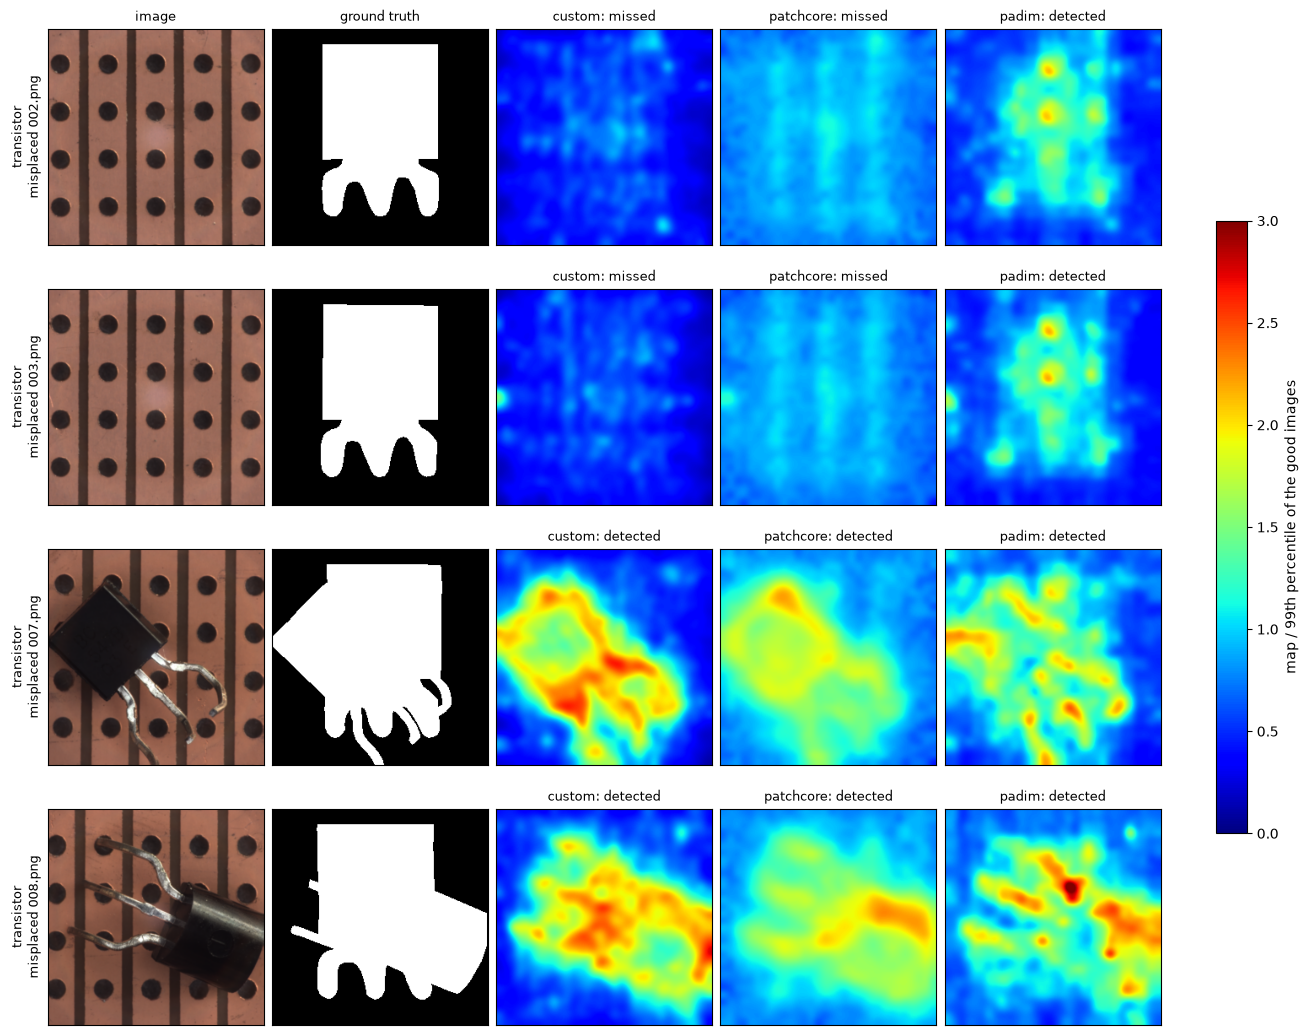

In [24]:
misplaced = scores[(scores['class'] == 'transistor') & (scores.defect_type == 'misplaced')]
plot_maps(pick(misplaced, 2, 'custom') + pick(misplaced, 2, 'custom', largest=True), 'global_anomalies.png')

- First two images: the transistor is missing. The maps of the custom model and of PatchCore stay in the normal range everywhere and both models miss the anomalies. Only PaDiM highlights the empty area.
- Last two images: the transistor is present but rotated or shifted. All three models detect them, with strong
  responses on the component. The difference is between an anomaly of *position* and an anomaly of *absence*. Every model sees that the transistor is shifted, but they behave differently where the transistor is missing:
  - the custom model reconstructs the features of the input: the empty board is a normal-looking input, so it is
    reconstructed well and the error stays low;
  - PatchCore compares each patch with the whole memory bank, regardless of position: the empty board finds close
    neighbors among the board patches of the training images;
  - PaDiM fits a Gaussian per position: at that position the training images always contain the transistor, so the
    board features are unlikely there. This is the reason why PaDiM is the only one to see also the missing part.

## 2.2: Localization
The weak point of the custom model is localization (AUPRO). For each defective image of transistor and tile (the
classes with the lowest AUPRO of the custom model) I compute a per-image pixel AUROC between map and ground truth,
a simple proxy of the localization quality. Rule: the 2 images per class where the custom model localizes worst
compared to PatchCore.

Loaded model weights from experiments\feature_reconstruction\layer23_multihead_c256\tile\checkpoints\best_model.pth
Random seed set to 42.


,custom,patchcore,padim
class,,,
tile,0.928,0.972,0.951
transistor,0.908,0.954,0.948


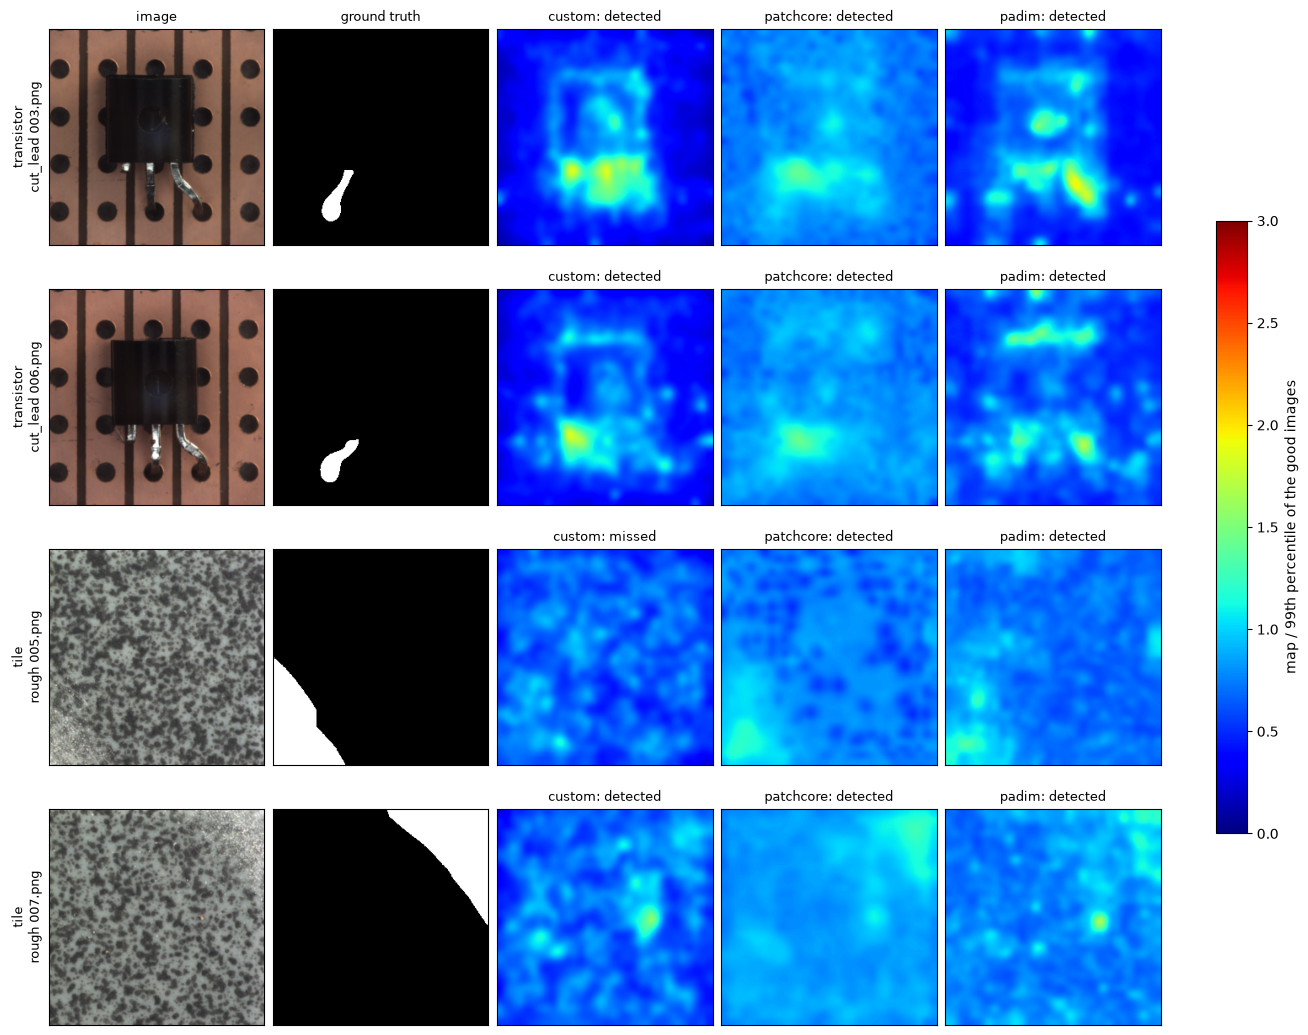

In [25]:
def pixel_auroc_per_image(cls):
    dataset, maps = class_maps(cls)
    rows = []
    for i, sample in enumerate(dataset.samples):
        if sample['label'] == 0:
            continue
        mask = dataset[i]['mask'][0].numpy().ravel() > 0.5
        row = {'class': cls, 'path': str(sample['rgb_path']), 'defect_type': sample['defect_type']}
        for model in MODELS:
            row[model] = roc_auc_score(mask, maps[model][i].ravel())
        rows.append(row)
    return pd.DataFrame(rows)


localization = pd.concat([pixel_auroc_per_image(cls) for cls in ['transistor', 'tile']], ignore_index=True)
localization['custom - patchcore'] = localization.custom - localization.patchcore
display(localization.groupby('class')[MODELS].mean().round(3))

selected = []
for cls in ['transistor', 'tile']:
    selected += pick(localization[localization['class'] == cls], 2, 'custom - patchcore')
plot_maps(selected, 'localization.png')

- transistor/cut_lead: the custom model detects both images and its strongest response is around the cut lead
  (clearly in the second image, where it is more precise than PatchCore and PaDiM, whose peaks are partly on the
  bent lead or on the top edge of the body). Its lower pixel AUROC comes from the secondary activations outside the defect: along the contour of the transistor body and on the base of the other leads. The pixel AUROC (and the AUPRO) count all these pixels as errors, while looking at the map one tends to look only at the peak.
  So the weak point of the custom model is not where it puts the peak, but its response to normal local structures
  such as the edges of the component.
- tile/rough: the defect is a large region with a slightly different, low-contrast texture at a corner of the image.
  PatchCore and PaDiM, have a spatially coherent response on that region; the custom model responds to
  isolated spots of the speckled pattern instead: it misses the first image, and detects the second one because of
  a spot in the middle of the tile, outside the defect.

## 2.3: Intrinsically difficult defect types
pill/crack and screw/manipulated_front are below 0.9 Image AUROC for all the models (section 1.3). To compare
models with different score scales, each score is replaced by its rank among the test images of the class (0 = most
normal, 1 = most anomalous). Rule: for each of the two types, the 2 images with the lowest mean rank over the three
models, i.e. the defects that all the models consider the most normal.

Loaded model weights from experiments\feature_reconstruction\layer23_multihead_c256\pill\checkpoints\best_model.pth
Random seed set to 42.
Loaded model weights from experiments\feature_reconstruction\layer23_multihead_c256\screw\checkpoints\best_model.pth
Random seed set to 42.


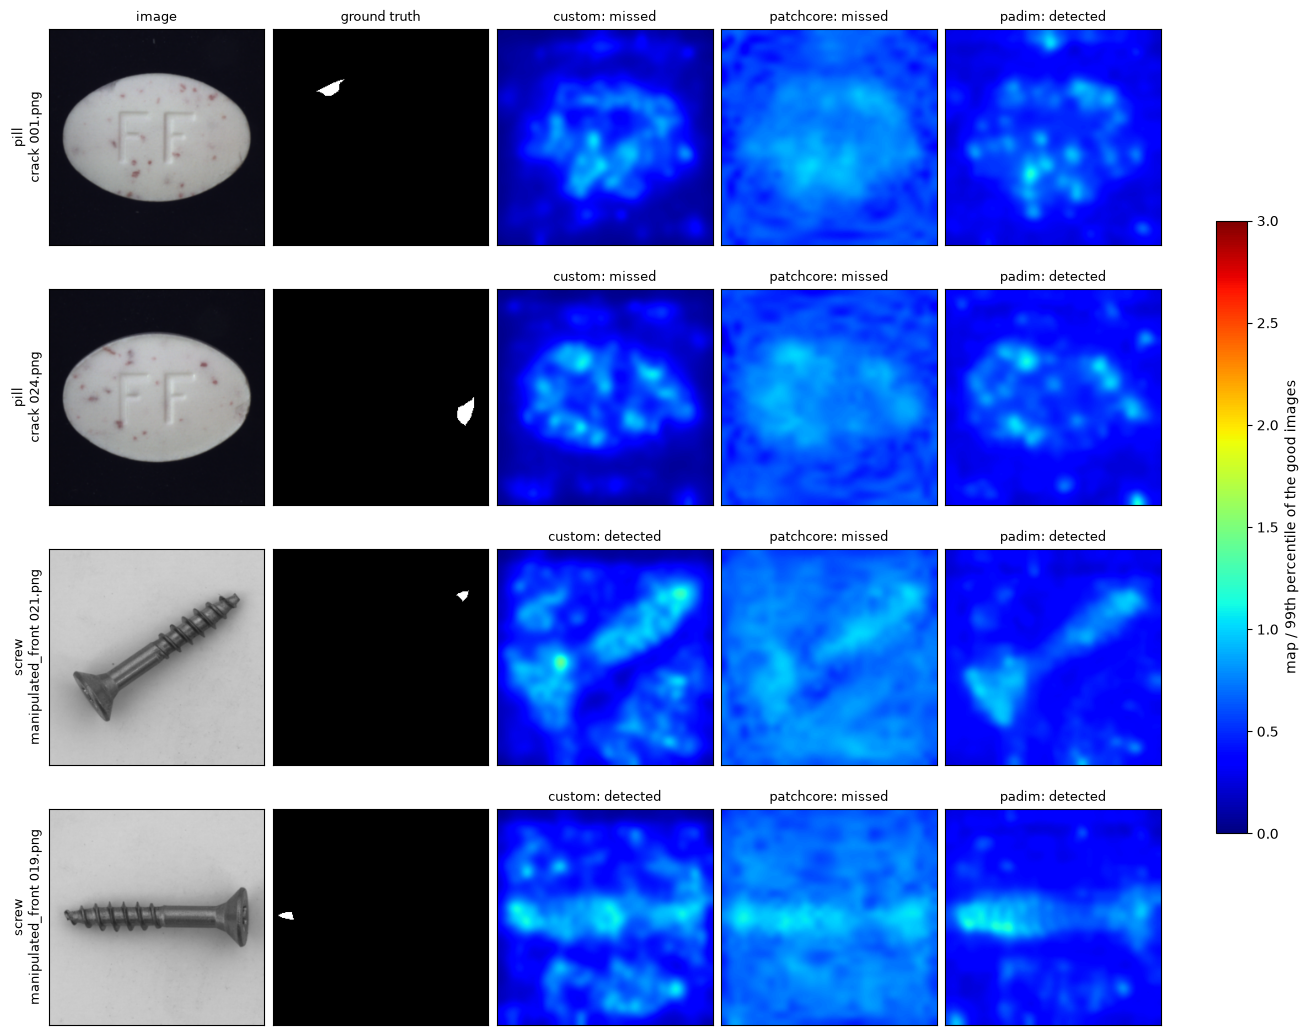

In [26]:
scores['mean_rank'] = scores.groupby('class')[MODELS].rank(pct=True).mean(axis=1)

selected = []
for cls, defect_type in [('pill', 'crack'), ('screw', 'manipulated_front')]:
    selected += pick(scores[(scores['class'] == cls) & (scores.defect_type == defect_type)], 2, 'mean_rank')
plot_maps(selected, 'intrinsic_difficulty.png')

- pill/crack: the cracks are tiny and at the edge of the pill. No map highlights them.
- screw/manipulated_front: the defect is a small deformation of the tip, while the screw appears with a different
  position and orientation in every image. The maps follow the whole screw; only the custom model has a weak
  response at the tip in the first screw image, weaker than its response near the head.
- When a model has the label "detected" on one of these images the peak of its map is not on the defect: the image score is above the threshold because of other regions, so the detection is right for the wrong reason.
- This supports the hypothesis of section 1.3: the defect is small compared to the normal variability of the object, which is a property of the data rather than of a method.

## 2.4: False positives of the custom model
In section 1.4 the extra errors of the custom model are false alarms on good images. Rule: among the good images
that the custom model misclassifies and PatchCore does not, the 4 with the highest custom rank in their class.

class
capsule        5
grid           4
pill           3
screw         13
tile           4
toothbrush     4
wood           2
zipper         4
Name: good images wrong only for custom, dtype: int64

Loaded model weights from experiments\feature_reconstruction\layer23_multihead_c256\capsule\checkpoints\best_model.pth
Random seed set to 42.
Loaded model weights from experiments\feature_reconstruction\layer23_multihead_c256\zipper\checkpoints\best_model.pth
Random seed set to 42.


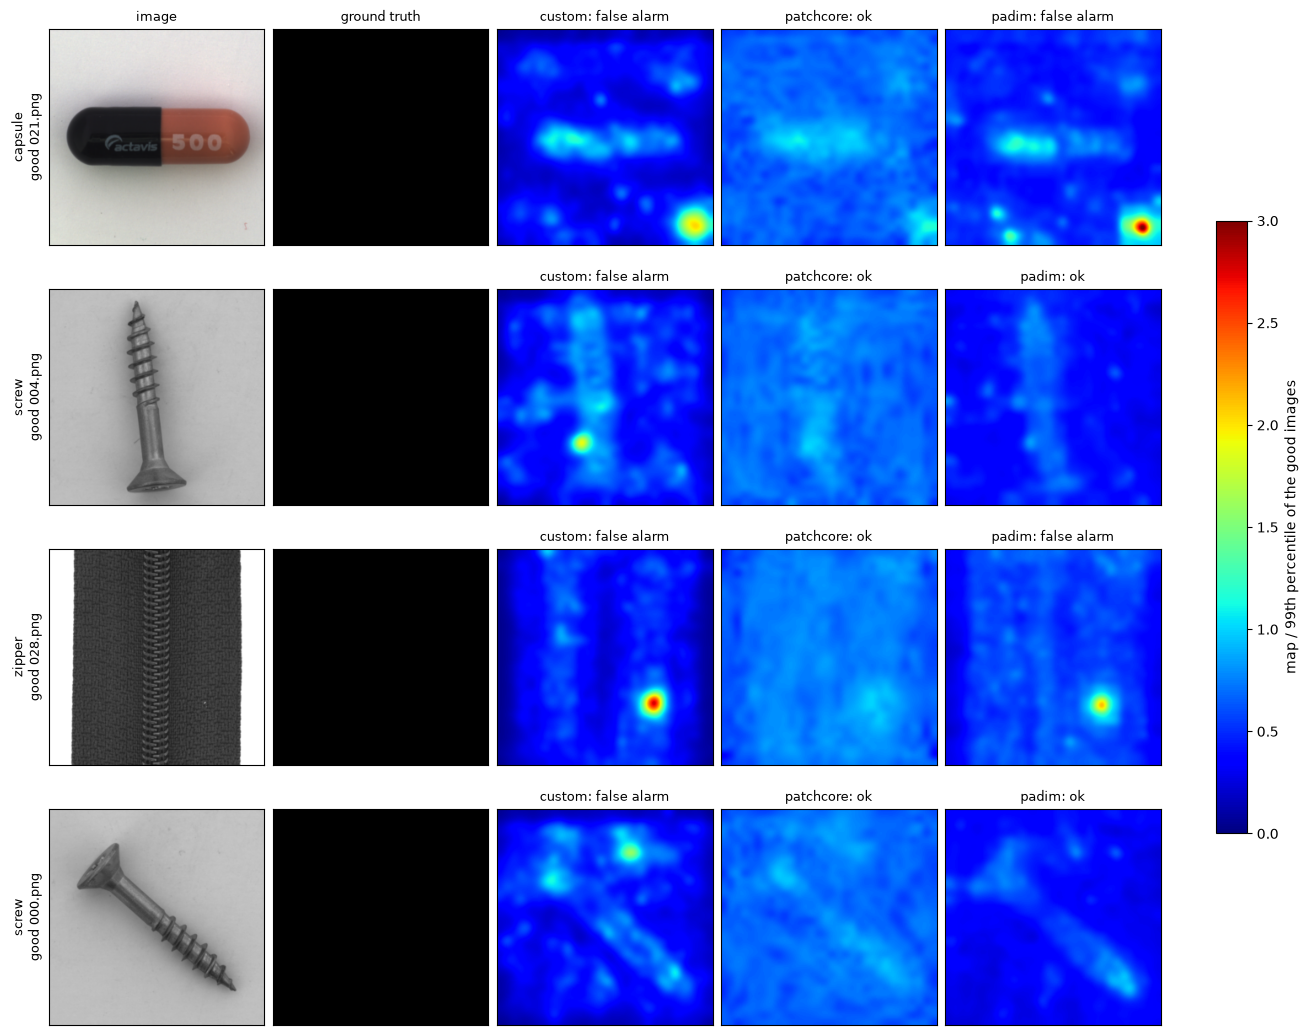

In [27]:
scores['custom_rank'] = scores.groupby('class')['custom'].rank(pct=True)
false_alarms = scores[(scores.label == 0) & scores.custom_wrong & ~scores.patchcore_wrong]
display(false_alarms.groupby('class').size().rename('good images wrong only for custom'))
plot_maps(pick(false_alarms, 4, 'custom_rank', largest=True), 'custom_false_positives.png')

- In all four images the peak of the custom model falls on a small particle (dust or a short fiber), visible
  when zooming on the original image. They are real irregularities w.r.t. good images, but they are not industrial defects so they count as false positives.
- PaDiM reacts to the same particles in the capsule and zipper images (and also raises a false alarm there), while
  PatchCore's maps stay smooth. A possible reason is that PatchCore averages each feature over a 3x3 neighborhood before comparing it with the memory bank, which dampens very small details; the custom model compares the features without this smoothing, so a tiny particle changes them enough to be reconstructed badly.